# Segments of invited women, for interventions

**Goal.** Split the invitations into a few groups that are (1) easy to explain, (2) assigned by simple rules on
information known when the invitation is sent, never on the outcome, and (3) different in *why* the woman does
not respond, so each group can get its own intervention.

**Rules** (`segments.py`, applied in order, the first match wins). They follow the three questions that drive response
in all models (`training/classifiers/explain`): *is she due*, *did she screen before*, *is she connected to
preventive care*.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score


sys.path.insert(0, ".")
from segments import COLUMNS, SEGMENTS, assign


DATA = Path("../data")
LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
extra = ["PERSON_ID", "INVITATION_DATE", "INVITATION_YEAR", "AGE_BAND", "KRAJ", "INVITATION_SEQUENCE",
         "PRIOR_SCREEN_COUNT_5Y", "GYN_REGISTERED_FLAG", "GP_REGISTERED", "GP_PREVENTION_24M_CNT",
         "DENTAL_PREVENTION_24M_CNT", "AGE_BAND_MEAN"]
df = pd.read_csv(DATA / "Rakhaton2026_prepared.csv", usecols=COLUMNS + LABELS + extra, dtype={"PERSON_ID": str})
df["SEGMENT"] = assign(df)
names = list(SEGMENTS)

INK2, GRID = "#52514e", "#e4e3df"
BLUE, RED = "#2a78d6", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left", "legend.frameon": False,
})
pd.set_option("display.max_colwidth", None)
pd.DataFrame({"segment": names, "rule": list(SEGMENTS.values())}).style.hide(axis="index")

segment,rule
A not due yet,screened < 24 months before the invitation
B first invitation,first invitation of the woman
"C lapsed screener, gynaecologist","screened before (>= 24 months ago), gynaecologist prevention visit in 2 years"
"D lapsed screener, no gynaecologist","screened before (>= 24 months ago), no gynaecologist prevention visit"
"E never screened, gynaecologist","repeat invitation, not screened in 5 years, gynaecologist prevention visit"
"F never screened, other screening","repeat, not screened, no gynaecologist visit, but other screening programme in 3 years"
"G never screened, healthcare user","repeat, not screened, no prevention, but some healthcare contact in 12 months"
H disconnected,"repeat, not screened, no prevention and no healthcare contact"


### The rules as a decision tree

The same rules drawn as the decision tree they are: each grey box is one yes/no question, asked in order; each coloured leaf is a segment, with its size, 12-month response (darker = higher) and suggested intervention. Unlike a fitted tree, every split here was chosen by hand to have a meaning (see `tree_diagram.py`, which also checks that the drawing matches `assign()` exactly).

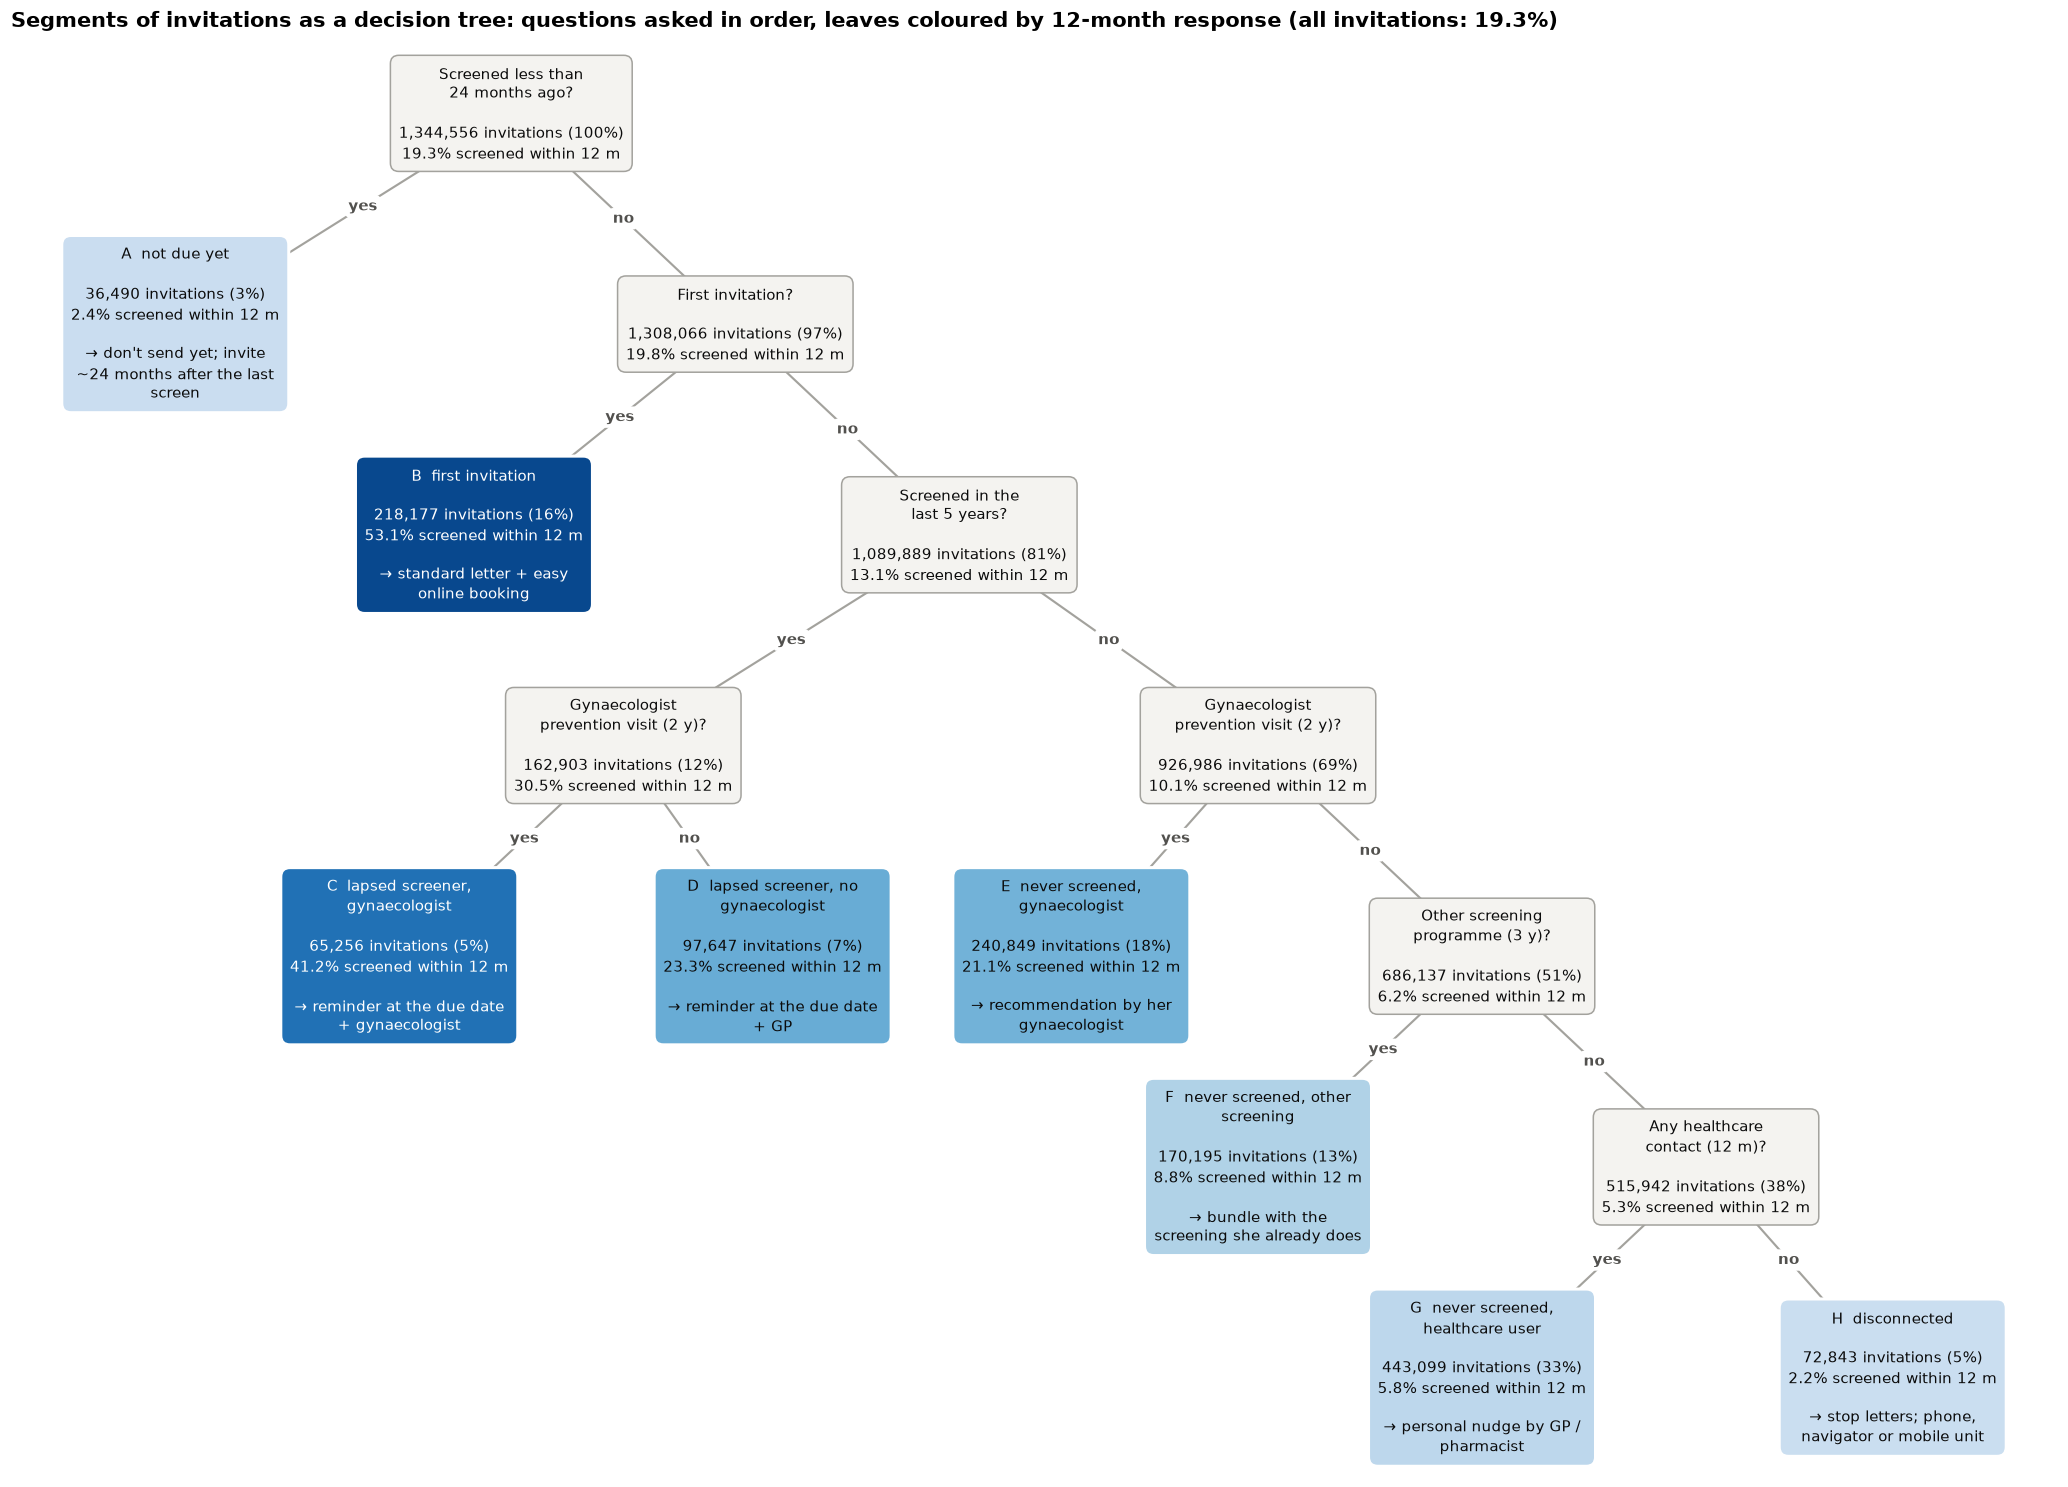

In [2]:
from tree_diagram import draw_segment_tree


draw_segment_tree(df, Path("segment_tree.png"))
plt.show()

## 1. Size and response of each segment

In [3]:
latest = df.sort_values("INVITATION_DATE").groupby("PERSON_ID").tail(1)  # each woman's most recent invitation
size = pd.DataFrame({
    "invitations": df.SEGMENT.value_counts(sort=False),
    "share of invitations": df.SEGMENT.value_counts(normalize=True, sort=False),
    "women (latest invitation)": latest.SEGMENT.value_counts(sort=False),
})
rates = df.groupby("SEGMENT", observed=False)[LABELS].mean().set_axis(["3M", "6M", "12M"], axis=1)
rates["fast share (3M / 12M)"] = rates["3M"] / rates["12M"]
summary = size.join(rates)
summary.loc["ALL"] = [len(df), 1.0, len(latest), *df[LABELS].mean(), df[LABELS[0]].mean() / df[LABELS[2]].mean()]
summary.style.format({"invitations": "{:,.0f}", "women (latest invitation)": "{:,.0f}",
                      "share of invitations": "{:.1%}", "3M": "{:.1%}", "6M": "{:.1%}", "12M": "{:.1%}",
                      "fast share (3M / 12M)": "{:.0%}"})

,invitations,share of invitations,women (latest invitation),3M,6M,12M,fast share (3M / 12M)
SEGMENT,,,,,,,
A not due yet,"36,490",2.7%,"33,350",1.4%,2.0%,2.4%,59%
B first invitation,"218,177",16.2%,"126,397",22.2%,37.3%,53.1%,42%
"C lapsed screener, gynaecologist","65,256",4.9%,"32,558",16.9%,28.0%,41.2%,41%
"D lapsed screener, no gynaecologist","97,647",7.3%,"35,535",6.6%,13.6%,23.3%,28%
"E never screened, gynaecologist","240,849",17.9%,"89,757",7.9%,13.5%,21.1%,38%
"F never screened, other screening","170,195",12.7%,"51,710",2.4%,4.9%,8.8%,28%
"G never screened, healthcare user","443,099",33.0%,"118,360",1.3%,3.0%,5.8%,23%
H disconnected,"72,843",5.4%,"20,860",0.4%,1.0%,2.2%,17%
ALL,"1,344,556",100.0%,"508,527",7.1%,12.5%,19.3%,37%


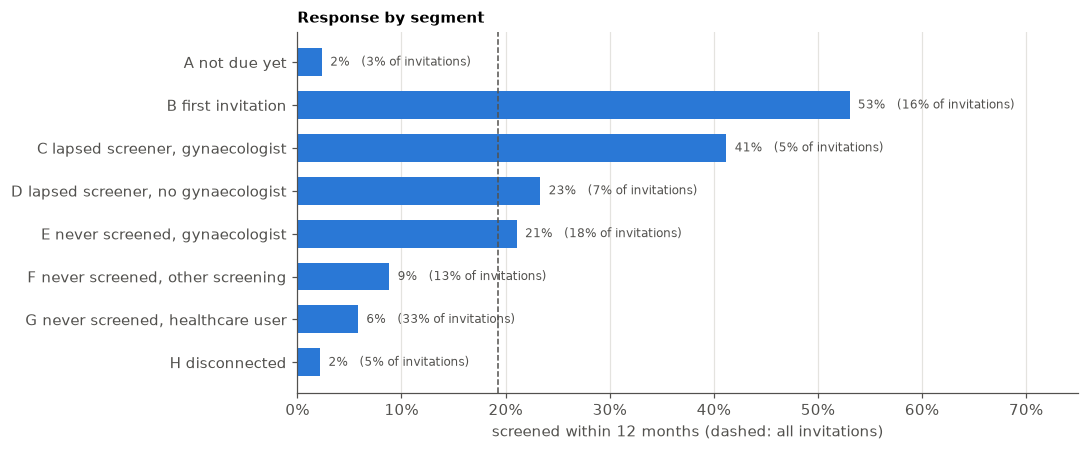

In [4]:
s = summary.drop("ALL")
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(s))[::-1]
ax.barh(y, s["12M"], color=BLUE, height=0.65)
ax.axvline(summary.loc["ALL", "12M"], color=INK2, lw=1, ls="--")
for yi, (rate, share) in zip(y, zip(s["12M"], s["share of invitations"], strict=True), strict=True):
    ax.text(rate + 0.008, yi, f"{rate:.0%}   ({share:.0%} of invitations)", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, s.index)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.75)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("screened within 12 months (dashed: all invitations)")
ax.set_title("Response by segment")
plt.tight_layout(); plt.show()

## 2. Who is in each segment

Profile at the invitation date: share of women aged 50+, average invitation sequence, registrations and
prevention habits. Percentages are shares of the segment's invitations.

In [5]:
g = df.groupby("SEGMENT", observed=False)
profile = pd.DataFrame({
    "aged 50+": g.AGE_BAND_MEAN.apply(lambda a: (a >= 50).mean()),
    "mean invitation sequence": g.INVITATION_SEQUENCE.mean(),
    "invitation 7+": g.INVITATION_SEQUENCE.apply(lambda s: (s >= 7).mean()),
    "GP registered": g.GP_REGISTERED.mean(),
    "gynaecologist registered": g.GYN_REGISTERED_FLAG.mean(),
    "GP prevention visit": g.GP_PREVENTION_24M_CNT.apply(lambda s: (s > 0).mean()),
    "dental prevention": g.DENTAL_PREVENTION_24M_CNT.apply(lambda s: (s > 0).mean()),
    "median healthcare contacts (12m)": g.HEALTHCARE_CONTACT_12M_CNT.median(),
})
pct = dict.fromkeys(profile.columns, "{:.0%}")
profile.style.format(pct | {"mean invitation sequence": "{:.1f}", "median healthcare contacts (12m)": "{:.0f}"})

,aged 50+,mean invitation sequence,invitation 7+,GP registered,gynaecologist registered,GP prevention visit,dental prevention,median healthcare contacts (12m)
SEGMENT,,,,,,,,
A not due yet,54%,2.6,8%,100%,94%,57%,74%,19
B first invitation,21%,1.0,0%,99%,93%,47%,74%,14
"C lapsed screener, gynaecologist",86%,2.1,1%,99%,97%,51%,72%,17
"D lapsed screener, no gynaecologist",95%,2.0,1%,99%,84%,44%,55%,13
"E never screened, gynaecologist",55%,5.0,30%,99%,96%,48%,69%,15
"F never screened, other screening",89%,6.8,60%,99%,71%,64%,49%,11
"G never screened, healthcare user",81%,6.7,59%,98%,64%,31%,45%,9
H disconnected,81%,7.0,63%,91%,50%,9%,8%,0


## 3. Repeated letters: when does another letter stop working?

12-month response by invitation sequence within each segment. Where the line is flat near zero, sending the same
letter again achieves little, so that is where a different channel should take over.

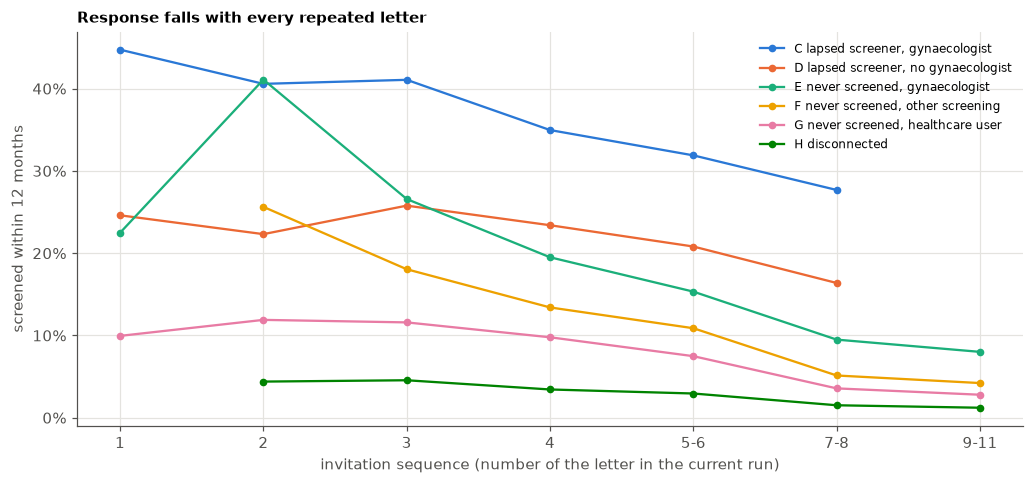

In [6]:
seq = pd.cut(df.INVITATION_SEQUENCE, [0, 1, 2, 3, 4, 6, 8, 11], labels=["1", "2", "3", "4", "5-6", "7-8", "9-11"])
decay = df.groupby(["SEGMENT", seq], observed=False).SCREENING_12M_FLAG.agg(["mean", "size"]).reset_index()
decay = decay[decay["size"] >= 500]
show = ["C lapsed screener, gynaecologist", "D lapsed screener, no gynaecologist", "E never screened, gynaecologist",
        "F never screened, other screening", "G never screened, healthcare user", "H disconnected"]
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for seg, color in zip(show, palette, strict=True):
    t = decay[seg == decay.SEGMENT]
    ax.plot(t.INVITATION_SEQUENCE.astype(str), t["mean"], marker="o", ms=4, color=color, label=seg)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("invitation sequence (number of the letter in the current run)")
ax.set_ylabel("screened within 12 months")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Response falls with every repeated letter")
plt.tight_layout(); plt.show()

## 4. Are the segments stable? 12-month response by year

In [7]:
by_year = df.pivot_table(index="SEGMENT", columns="INVITATION_YEAR", values="SCREENING_12M_FLAG", aggfunc="mean",
                         observed=False)
share_year = pd.crosstab(df.SEGMENT, df.INVITATION_YEAR, normalize="columns")
display(by_year.style.format("{:.1%}").set_caption("12M response"))
display(share_year.style.format("{:.1%}").set_caption("share of the year's invitations"))

INVITATION_YEAR,2020,2021,2022,2023,2024
SEGMENT,,,,,
A not due yet,2.2%,2.3%,2.2%,2.6%,2.4%
B first invitation,48.1%,53.5%,54.4%,54.8%,55.1%
"C lapsed screener, gynaecologist",36.2%,41.0%,42.8%,42.5%,43.3%
"D lapsed screener, no gynaecologist",19.6%,23.6%,24.5%,24.4%,24.8%
"E never screened, gynaecologist",20.2%,21.9%,21.5%,21.3%,20.5%
"F never screened, other screening",7.5%,8.9%,9.2%,9.3%,9.3%
"G never screened, healthcare user",5.1%,5.6%,5.8%,6.5%,6.1%
H disconnected,2.0%,1.8%,1.3%,2.7%,2.6%


INVITATION_YEAR,2020,2021,2022,2023,2024
SEGMENT,,,,,
A not due yet,2.3%,3.0%,2.7%,2.6%,3.0%
B first invitation,17.7%,16.9%,16.3%,15.5%,14.6%
"C lapsed screener, gynaecologist",4.7%,4.8%,4.9%,5.0%,5.0%
"D lapsed screener, no gynaecologist",7.4%,7.8%,7.8%,7.1%,6.1%
"E never screened, gynaecologist",16.5%,16.9%,17.5%,18.9%,19.9%
"F never screened, other screening",13.1%,12.6%,12.1%,12.3%,13.2%
"G never screened, healthcare user",31.6%,33.7%,35.3%,32.4%,31.6%
H disconnected,6.7%,4.3%,3.4%,6.3%,6.6%


## 5. Where are they? Segment mix by region (kraj)

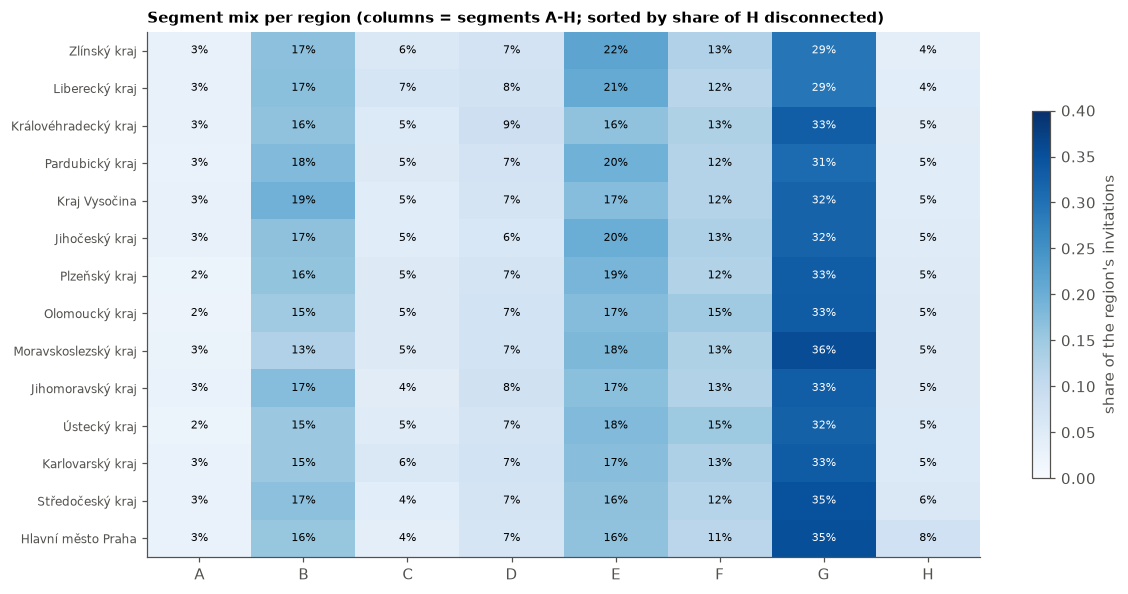

In [8]:
mix = pd.crosstab(df.KRAJ, df.SEGMENT, normalize="index")
mix = mix.loc[mix["H disconnected"].sort_values().index]
fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(mix.to_numpy(), cmap="Blues", vmin=0, vmax=0.4, aspect="auto")
ax.set_xticks(range(mix.shape[1]), [c.split(" ", 1)[0] for c in mix.columns])
ax.set_yticks(range(mix.shape[0]), mix.index, fontsize=8)
ax.grid(False)
for i in range(mix.shape[0]):
    for j in range(mix.shape[1]):
        ax.text(j, i, f"{mix.iat[i, j]:.0%}", ha="center", va="center", fontsize=7,
                color="white" if mix.iat[i, j] > 0.28 else "black")
fig.colorbar(im, ax=ax, shrink=0.7, label="share of the region's invitations")
ax.set_title("Segment mix per region (columns = segments A-H; sorted by share of H disconnected)")
plt.tight_layout(); plt.show()

## 6. How much of the predictive signal do 8 rules capture?

Score every test invitation with its segment's response rate from the train split, and compare its ROC AUC with
the best model's (gradient boosting, 0.841).

In [9]:
splits = {n: pd.read_csv(DATA / "splits" / f"{n}.csv", usecols=COLUMNS + LABELS) for n in ["train", "test"]}
for d in splits.values():
    d["SEGMENT"] = assign(d)
rows = []
for label in LABELS:
    rate = splits["train"].groupby("SEGMENT", observed=False)[label].mean()
    score = splits["test"].SEGMENT.map(rate).astype(float)
    rows.append({"label": label, "segments (8 rules)": roc_auc_score(splits["test"][label], score)})
pd.DataFrame(rows).assign(**{"gradient boosting (all features)": [0.841, 0.839, 0.841]}).set_index("label")\
    .style.format("{:.3f}")

,segments (8 rules),gradient boosting (all features)
label,,
SCREENING_3M_FLAG,0.795,0.841
SCREENING_6M_FLAG,0.792,0.839
SCREENING_12M_FLAG,0.793,0.841


## 7. Suggested interventions

Each segment has a different likely reason for not responding, and so a different channel that could reach it. The
interventions below are **hypotheses derived from the data**: the data shows *who* responds, not *what would
change* their behaviour. Each one should be tested with a randomized comparison inside its segment (part of the
women get the intervention, the rest the standard letter). Only that measures the real gain (uplift); see tasks 3–4.

| segment | invitations | 12M response | likely reason | suggested intervention |
|---|---|---|---|---|
| **A not due yet** | 2.7% | 2% | screened in the last few months; the letter comes too early | **Do not send** (or postpone to ~24 months after the last screen). Fixes a timing error and saves letters. |
| **B first invitation** | 16% | 53% | new to the programme, motivated | Keep the standard letter, and make booking easy (online / pre-booked slot). Highest yield per letter. |
| **C lapsed screener, gynaecologist** | 5% | 41% | regular screener who is overdue | **Timely reminder** at ~24–30 months (SMS / e-mail), and a reminder from her gynaecologist. |
| **D lapsed screener, no gynaecologist** | 7% | 23% | screened before, 95% aged 50+, weaker contact with care | Reminder at the due date plus **GP involvement** (GP-signed letter, mention at the next visit). |
| **E never screened, gynaecologist** | 18% | 21% | sees a gynaecologist preventively (96% registered), but no mammography | **Gynaecologist recommendation / referral** at the preventive visit. Largest reachable group: 241k invitations, about 90k women. Switch to this channel after ~3 ignored letters (response falls from 41% at the 2nd letter to 9% by the 7th). |
| **F never screened, other screening** | 13% | 9% | takes part in other screening programmes (64% GP prevention) | **Bundle** with the screening she already does: a joint invitation or a mention by the GP at the other screening. |
| **G never screened, healthcare user** | 33% | 6% | uses healthcare (median 9 contacts a year) but no prevention | **GP / pharmacist nudge**: personal recommendation at a routine visit; message aimed at women who have never screened. Largest segment (443k invitations, about 118k women). |
| **H disconnected** | 5% | 2% | no healthcare contact in a year; only 9% GP prevention and 8% dental | Letters barely work (2%, 0.4% within 3 months). **Stop repeating the letter**; test a different channel: phone call, patient navigator / community outreach, mobile screening unit. |

**Across segments**
- **Repeated letters lose effect.** In every never-screened segment, response falls with each repeated letter. After
  the 3rd–4th letter, switching channel is more promising than another letter.
- **Where to spend effort.** Segments B and C respond well already. The largest *volume* of non-response sits in E
  and G (51% of invitations together). E has an existing channel (the gynaecologist), which makes it the most
  promising target for a first pilot.
- **Regions** have a similar segment mix. Prague has the most disconnected women (8%), and Moravskoslezský the most
  healthcare users without prevention (36%) and the fewest first invitations (13%), which fits its low overall
  response.
- The 8 rules capture most of the signal: ranking invitations by segment reaches ROC AUC 0.79 (best model 0.84). The
  segments are simple enough to use in practice without a model, and stable across 2021–2024.